# GHAgentCI 1: getting started

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/unlv-evol/cai-miner/blob/main/notebooks/01-getting-started.ipynb)

GHAgentCI records the history of every GitHub Actions workflow file that invokes a coding agent (Claude, Copilot, Codex, Gemini, ...) in 196,253 mined GitHub repositories. This notebook introduces the tables, loads them, shows how they join, and reproduces the headline numbers reported in the paper.

**Dataset:** GHAgentCI, [https://doi.org/10.5281/zenodo.24088832](https://doi.org/10.5281/zenodo.24088832). **Field-by-field documentation:** [docs/DATASET.md](https://github.com/unlv-evol/cai-miner/blob/main/docs/DATASET.md).

The first code cell downloads each file from Zenodo once and caches it in a local folder (`ghagentci-data`, or the folder named by the `GHAGENTCI_DATA` environment variable).

In [1]:
import os
import urllib.request
from pathlib import Path

RECORD = "https://zenodo.org/records/24088832/files"
DATA = Path(os.environ.get("GHAGENTCI_DATA", "ghagentci-data"))


def fetch(name):
    path = DATA / name
    if not path.exists():
        DATA.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{RECORD}/{name}?download=1", path)
    return path

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

# One small palette for every chart in these notebooks.
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#4a3aa7",
    "#e34948",
)
GREY = "#8a8985"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4),
        "figure.dpi": 100,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.prop_cycle": plt.cycler(
            color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
        ),
    }
)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

## The tables

| table | one row is |
|---|---|
| `repositories` | a repository of the sampling frame, agentic or not (failed ones included) |
| `revisions` | one change (add, modify, rename, delete) to a workflow file whose history is agentic at some point |
| `steps` | one agent invocation inside one revision |
| `ghaw_manifests` | one revision of a GitHub Agentic Workflows (gh-aw) artifact |
| `frame` | the sampling frame: repository metadata from SEART (stars, language, creation date, ...) |

The workflow files themselves are in `content.tar.gz` (808 MB); notebook 4 shows how to read them.
List-valued columns are `|`-separated, and dates carry the committer's UTC offset, so we parse
them with `utc=True`.

In [3]:
repos = pd.read_csv(fetch("repositories.csv.gz"), low_memory=False)
revisions = pd.read_csv(fetch("revisions.csv.gz"), low_memory=False)
steps = pd.read_csv(fetch("steps.csv.gz"), low_memory=False)
manifests = pd.read_csv(fetch("ghaw_manifests.csv.gz"), low_memory=False)
frame = pd.read_csv(fetch("frame-2026-10-03.csv.gz"), low_memory=False)

for df in (revisions, steps, manifests):
    df["commit_date"] = pd.to_datetime(df["commit_date"], utc=True)

pd.DataFrame(
    {
        name: df.shape
        for name, df in [
            ("repositories", repos),
            ("revisions", revisions),
            ("steps", steps),
            ("ghaw_manifests", manifests),
            ("frame", frame),
        ]
    },
    index=["rows", "columns"],
).T

,rows,columns
repositories,196938,13
revisions,159878,28
steps,205832,20
ghaw_manifests,36657,33
frame,196938,9


## `repositories`: the denominator

Every repository of the frame has a row. `status` says whether mining succeeded: `ok`,
`incomplete` (some workflow blobs could not be read), or a failure. Repositories without any
agentic workflow have zeros and empty agent columns.

In [4]:
print(repos["status"].value_counts().to_string())
repos[repos["n_agentic_files"] > 0].head(3)

status
ok              196253
clone-failed       675
error                6
excluded             4


,repository,n_commits,n_workflow_files,n_workflow_revisions,n_agentic_files,n_agentic_revisions,agents,first_agentic_date,last_agentic_date,n_blobs_requested,n_blobs_read,n_blobs_missing,status
4,langwatch/langwatch,6944.0,77.0,954.0,1,2,codex,2025-10-31T11:44:44+01:00,2025-11-06T11:28:38+01:00,926.0,926.0,0.0,ok
42,lucien144/fyx,1286.0,6.0,24.0,5,15,claude,2026-06-21T20:46:39+02:00,2026-07-19T23:52:19+02:00,22.0,22.0,0.0,ok
205,kasianov-mikhail/scout,1672.0,20.0,223.0,2,3,claude,2026-04-17T16:24:42+03:00,2026-04-17T16:41:04+03:00,201.0,201.0,0.0,ok


## `revisions`: file histories

A *file history* is identified by `(repository, uid)`; `uid` survives renames. Once any revision of a
file is agentic, the whole history is included, including revisions before the agent was added and
after it was removed. `agentic` is true when a revision has strong evidence for a named agent.
Here is one short history, in time order (author names and hashed e-mails omitted).

In [5]:
cols = [
    "commit_date",
    "git_change_type",
    "file_path",
    "workflow_name",
    "triggers",
    "n_jobs",
    "n_steps",
    "strong_agents",
    "agentic",
    "actor_gated",
]
sizes = revisions.groupby(["repository", "uid"]).size()
repo, uid = sizes[sizes == 4].index[0]
revisions[(revisions["repository"] == repo) & (revisions["uid"] == uid)].sort_values("commit_date")[
    cols
]

,commit_date,git_change_type,file_path,workflow_name,triggers,n_jobs,n_steps,strong_agents,agentic,actor_gated
139258,2025-12-15 16:12:39+00:00,Added,.github/workflows/pr-agent.yml,PR-Agent,pull_request|issue_comment,1.0,1.0,pr_agent,True,True
139257,2025-12-15 16:20:48+00:00,Modified,.github/workflows/pr-agent.yml,PR-Agent,pull_request|issue_comment|issues,1.0,1.0,pr_agent,True,True
139256,2025-12-15 16:23:59+00:00,Modified,.github/workflows/pr-agent.yml,PR-Agent,pull_request|issue_comment,1.0,1.0,NaN,False,True
139255,2025-12-15 16:33:06+00:00,Modified,.github/workflows/pr-agent.yml,PR-Agent,pull_request|issue_comment,1.0,1.0,NaN,False,True


## `steps`: agent invocations

One row per invocation. `evidence_kind` tells how the agent was recognised: `uses` (a Marketplace
action), `run` (a CLI in a shell step), `path` (a reserved file name), `ghaw` (a gh-aw artifact) are
strong; `env`, `url`, `job` are weak. Rows exist only for agentic revisions.

In [6]:
print(steps["evidence_kind"].value_counts().to_string())
steps[
    [
        "repository",
        "agent",
        "scope",
        "evidence_kind",
        "job_id",
        "step_index",
        "action",
        "action_version",
        "triggers",
        "tasks",
    ]
].head(5)

evidence_kind
uses    69104
run     64822
ghaw    36657
env     24507
path     8805
url      1937


,repository,agent,scope,evidence_kind,job_id,step_index,action,action_version,triggers,tasks
0,langwatch/langwatch,codex,file,env,auto-fix,NaN,NaN,NaN,workflow_run|workflow_dispatch,implement|on_demand
1,langwatch/langwatch,codex,step,uses,auto-fix,4.0,openai/codex-action,main,workflow_run|workflow_dispatch,implement|on_demand
2,langwatch/langwatch,codex,step,env,auto-fix,6.0,NaN,NaN,workflow_run|workflow_dispatch,implement|test|on_demand
3,langwatch/langwatch,gemini,step,env,auto-fix,6.0,NaN,NaN,workflow_run|workflow_dispatch,implement|test|on_demand
4,langwatch/langwatch,codex,file,env,auto-fix,NaN,NaN,NaN,workflow_run|workflow_dispatch,implement|on_demand


## How the tables join

* `repository` joins everything (and `frame.name` = `repositories.repository`);
* `(repository, uid)` is a file history;
* `(repository, uid, commit_hash)` is a revision, so every `steps` and `ghaw_manifests` row has
  exactly one matching `revisions` row;
* `content_sha256` names the revision's file in `content.tar.gz`.

We check these properties rather than take them on trust.

In [7]:
REV = ["repository", "uid", "commit_hash"]
assert not revisions.duplicated(REV).any(), "a revision key repeats"

joined = steps.merge(revisions[REV + ["agentic"]], on=REV, how="left", validate="many_to_one")
print("steps without a revision:", joined["agentic"].isna().sum())
print("steps on non-agentic revisions:", (joined["agentic"] == False).sum())

m = manifests.merge(revisions[REV], on=REV, how="left", indicator=True)
print("manifest rows without a revision:", (m["_merge"] != "both").sum())

print(
    "mined repositories missing from the frame:", (~repos["repository"].isin(frame["name"])).sum()
)

steps without a revision: 0
steps on non-agentic revisions: 11
manifest rows without a revision: 0
mined repositories missing from the frame: 0


## Headline numbers

The paper reports five headline counts. Each is computed from the tables and compared with
the published value:

* **mined repositories**: status `ok` or `incomplete`;
* **agentic repositories**: repositories with at least one agentic revision;
* **agentic workflow histories**: distinct `(repository, uid)` in `revisions`;
* **invocations**: rows of `steps`;
* **gh-aw repositories**: agentic repositories with a gh-aw manifest.

In [8]:
agentic_repos = set(revisions.loc[revisions["agentic"], "repository"])
computed = {
    "mined repositories": repos["status"].isin(["ok", "incomplete"]).sum(),
    "agentic repositories": len(agentic_repos),
    "agentic workflow histories": len(revisions[["repository", "uid"]].drop_duplicates()),
    "invocations": len(steps),
    "repositories using gh-aw": len(set(manifests["repository"]) & agentic_repos),
}
expected = {
    "mined repositories": 196_253,
    "agentic repositories": 6_345,
    "agentic workflow histories": 15_928,
    "invocations": 205_832,
    "repositories using gh-aw": 506,
}
headline = pd.DataFrame({"computed": computed, "paper": expected})
headline["matches"] = headline["computed"] == headline["paper"]
headline

,computed,paper,matches
mined repositories,196253,196253,True
agentic repositories,6345,6345,True
agentic workflow histories,15928,15928,True
invocations,205832,205832,True
repositories using gh-aw,506,506,True


The other tables tell the same story: `repositories` marks exactly the same repositories as
agentic, and so does `steps`.

In [9]:
print(
    "repositories with agentic revisions (repositories table):",
    (repos["n_agentic_revisions"] > 0).sum(),
)
print("repositories with an invocation (steps table):", steps["repository"].nunique())
print(
    "share of mined repositories that are agentic: "
    f"{len(agentic_repos) / computed['mined repositories']:.2%}"
)

repositories with agentic revisions (repositories table): 6345
repositories with an invocation (steps table): 6345
share of mined repositories that are agentic: 3.23%


## Invocations and repositories per agent

`agent` is the agent group. `unknown` is a gh-aw lock file whose header does not name its engine
(older gh-aw compilers did not write it); these are certain gh-aw artifacts. A repository can use
several agents, so the repository column does not sum to 6,345.

In [10]:
per_agent = (
    steps.groupby("agent")
    .agg(invocations=("repository", "size"), repositories=("repository", "nunique"))
    .sort_values("repositories", ascending=False)
)
per_agent

,invocations,repositories
agent,,
claude,125254,4293
copilot,33233,1706
codex,21394,588
unknown,12483,363
gemini,9870,317
pr_agent,939,110
cursor,2242,65
coderabbit,64,27
aider,239,15


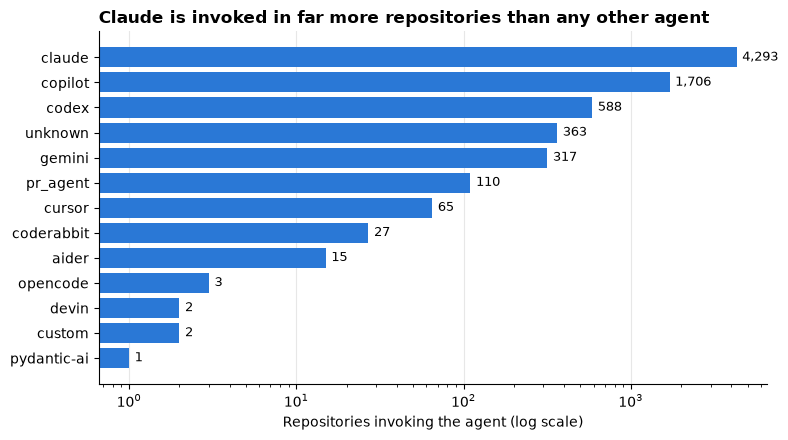

In [11]:
top = per_agent["repositories"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top.values, color=BLUE)
ax.set_xscale("log")
for y, v in enumerate(top.values):
    ax.text(v * 1.08, y, f"{v:,}", va="center", fontsize=9)
ax.set_xlabel("Repositories invoking the agent (log scale)")
ax.set_title("Claude is invoked in far more repositories than any other agent")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## Things to know before analysing

* Counting **invocations** weights repositories with many workflows and long histories heavily;
  counting **repositories** or **histories** usually answers adoption questions better.
* `steps` includes weak-evidence invocations (`env`, `url`, `job`) found in agentic revisions;
  filter on `evidence_kind` when only strong evidence should count.
* The join check above finds 11 `steps` rows on revisions whose `agentic` flag is false, although
  rows are meant to exist for agentic revisions only. All are weak `env` evidence for Claude in one
  repository, in revisions whose only strong evidence was the `generic_ai` group that the release
  removes. They are part of the 205,832 invocations the paper counts.
* `git_change_type` has a fifth value, `T`, on a few rows: git's *type change*, here symbolic links
  in `elastic/ai-github-actions` replaced by regular files.

In [12]:
revisions["git_change_type"].value_counts()

git_change_type
Modified    137267
Added        15928
Deleted       5988
Renamed        677
T               18
Name: count, dtype: int64

Next: [02-adoption-over-time](02-adoption-over-time.ipynb) looks at when repositories adopt
agents and whether they keep them.